In [1]:
!pip install -q scikit-fuzzy numpy matplotlib pandas

In [2]:
%%writefile mamdani_energy.py
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

class MamdaniEnergyModel:
    def __init__(self):
        self.heat_univ = np.linspace(0, 100, 201)     # рівень тепловтрат
        self.elec_univ = np.linspace(0, 1000, 201)    # інтенсивність використання електроенергії
        self.eff_univ = np.linspace(0, 100, 201)      # інтегральний коефіцієнт ефективності

        self.heat = ctrl.Antecedent(self.heat_univ, "heat_loss")
        self.elec = ctrl.Antecedent(self.elec_univ, "electricity")
        self.eff = ctrl.Consequent(self.eff_univ, "efficiency")

        self.heat["low"] = fuzz.trapmf(self.heat_univ, [0, 0, 25, 45])
        self.heat["medium"] = fuzz.trimf(self.heat_univ, [30, 50, 70])
        self.heat["high"] = fuzz.trapmf(self.heat_univ, [55, 75, 100, 100])

        self.elec["low"] = fuzz.trapmf(self.elec_univ, [0, 0, 250, 450])
        self.elec["medium"] = fuzz.trimf(self.elec_univ, [300, 500, 700])
        self.elec["high"] = fuzz.trapmf(self.elec_univ, [550, 750, 1000, 1000])

        self.eff["low"] = fuzz.trapmf(self.eff_univ, [0, 0, 25, 45])
        self.eff["medium"] = fuzz.trimf(self.eff_univ, [35, 55, 75])
        self.eff["high"] = fuzz.trapmf(self.eff_univ, [65, 80, 100, 100])

        rules = [
            ctrl.Rule(self.heat["low"] & self.elec["low"], self.eff["high"]),
            ctrl.Rule(self.heat["low"] & self.elec["medium"], self.eff["high"]),
            ctrl.Rule(self.heat["low"] & self.elec["high"], self.eff["medium"]),
            ctrl.Rule(self.heat["medium"] & self.elec["low"], self.eff["high"]),
            ctrl.Rule(self.heat["medium"] & self.elec["medium"], self.eff["medium"]),
            ctrl.Rule(self.heat["medium"] & self.elec["high"], self.eff["low"]),
            ctrl.Rule(self.heat["high"] & self.elec["low"], self.eff["medium"]),
            ctrl.Rule(self.heat["high"] & self.elec["medium"], self.eff["low"]),
            ctrl.Rule(self.heat["high"] & self.elec["high"], self.eff["low"]),
        ]

        self.system = ctrl.ControlSystem(rules)
        self.sim = ctrl.ControlSystemSimulation(self.system)

    def predict(self, heat_val, elec_val):
        self.sim.input["heat_loss"] = float(np.clip(heat_val, 0, 100))
        self.sim.input["electricity"] = float(np.clip(elec_val, 0, 1000))
        self.sim.compute()
        return float(self.sim.output["efficiency"])

Writing mamdani_energy.py


In [3]:
%%writefile tsukamoto_energy.py
import numpy as np
import skfuzzy as fuzz

class TsukamotoEnergyModel:
    def __init__(self):
        self.heat_univ = np.linspace(0, 100, 201)
        self.elec_univ = np.linspace(0, 1000, 201)
        self.eff_univ = np.linspace(0, 100, 201)

        self.heat_mf = {
            "low": fuzz.trapmf(self.heat_univ, [0, 0, 25, 45]),
            "medium": fuzz.trimf(self.heat_univ, [30, 50, 70]),
            "high": fuzz.trapmf(self.heat_univ, [55, 75, 100, 100]),
        }
        self.elec_mf = {
            "low": fuzz.trapmf(self.elec_univ, [0, 0, 250, 450]),
            "medium": fuzz.trimf(self.elec_univ, [300, 500, 700]),
            "high": fuzz.trapmf(self.elec_univ, [550, 750, 1000, 1000]),
        }

        self.eff_mono_mf = {
            "low": fuzz.trapmf(self.eff_univ, [0, 0, 0, 50]),
            "medium": fuzz.trapmf(self.eff_univ, [25, 75, 100, 100]),
            "high": fuzz.trapmf(self.eff_univ, [55, 100, 100, 100]),
        }

        self.rules = [
            ("low", "low", "high"),
            ("low", "medium", "high"),
            ("low", "high", "medium"),
            ("medium", "low", "high"),
            ("medium", "medium", "medium"),
            ("medium", "high", "low"),
            ("high", "low", "medium"),
            ("high", "medium", "low"),
            ("high", "high", "low"),
        ]

    @staticmethod
    def _inverse_monotonic(term, alpha):
        if term == "low":
            return 50.0 * (1.0 - alpha)
        if term == "medium":
            return 25.0 + 50.0 * alpha
        return 55.0 + 45.0 * alpha

    def predict(self, heat_val, elec_val):
        h_val = float(np.clip(heat_val, 0, 100))
        e_val = float(np.clip(elec_val, 0, 1000))

        mu_h = {t: fuzz.interp_membership(self.heat_univ, mf, h_val) for t, mf in self.heat_mf.items()}
        mu_e = {t: fuzz.interp_membership(self.elec_univ, mf, e_val) for t, mf in self.elec_mf.items()}

        num = 0.0
        den = 0.0
        for h_term, e_term, out_term in self.rules:
            alpha = min(mu_h[h_term], mu_e[e_term])
            if alpha > 0:
                z_i = self._inverse_monotonic(out_term, alpha)
                num += alpha * z_i
                den += alpha

        return float(num / den) if den > 0 else 50.0

Writing tsukamoto_energy.py


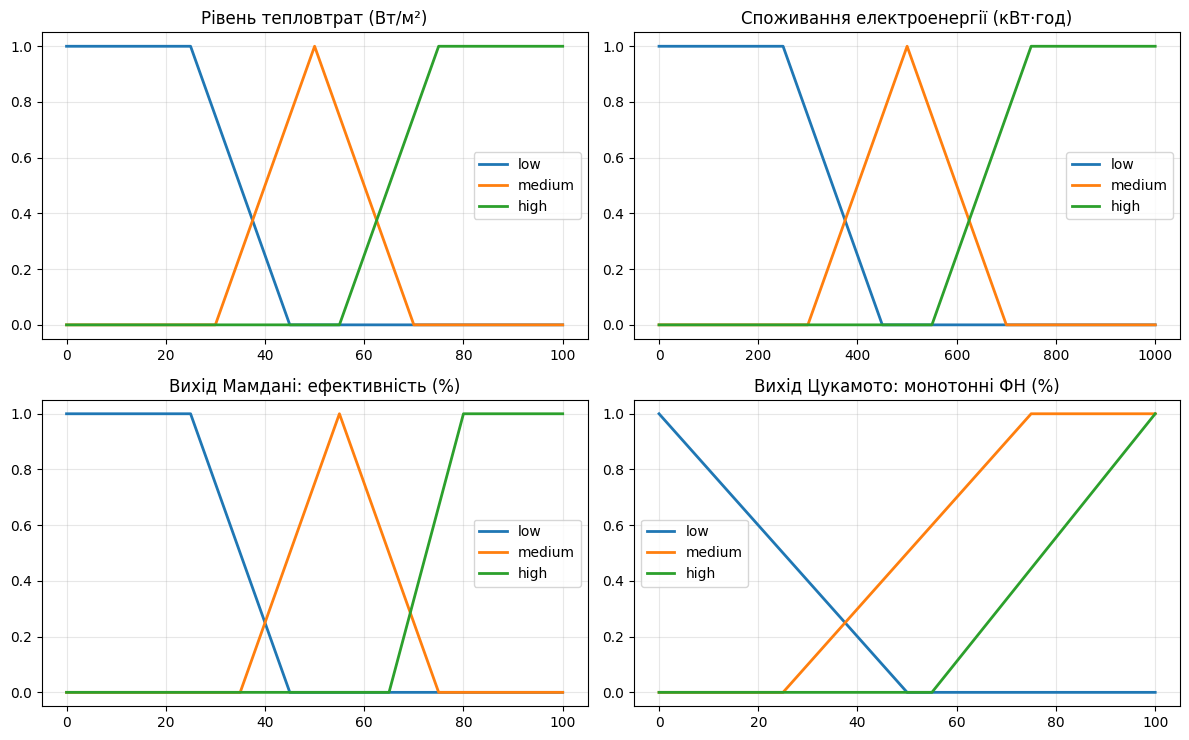

                              Сценарій  Тепловтрати, Вт/м²  Електроенергія, кВт·год  Мамдані, %  Цукамото, %  Різниця |Δ|, %
                   Дуже низькі витрати                  15                      180       85.91       100.00           14.09
Низькі тепловтрати, середнє споживання                  25                      480       85.61        95.50            9.89
                       Помірні витрати                  40                      350       74.03        65.00            9.03
            Середній номінальний режим                  50                      500       55.00        75.00           20.00
                Підвищене навантаження                  60                      650       30.30        32.50            2.20
 Високі тепловтрати, помірна електрика                  75                      400       30.30        29.17            1.14
              Критичні витрати енергії                  85                      880       17.98         0.00           17.98


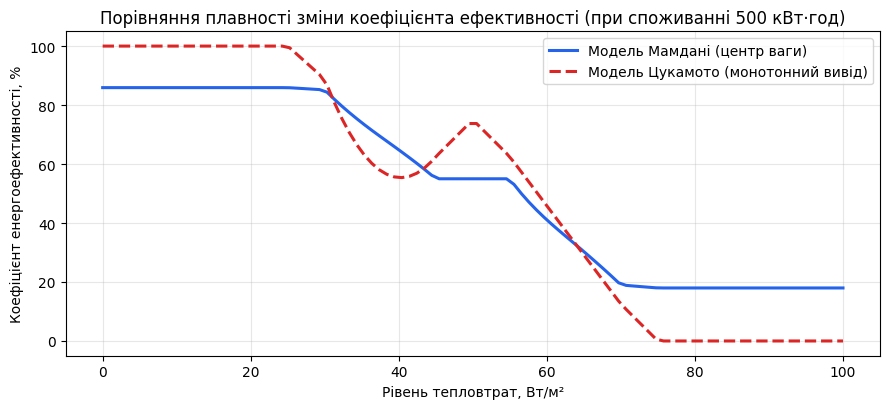

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mamdani_energy import MamdaniEnergyModel
from tsukamoto_energy import TsukamotoEnergyModel

mamdani = MamdaniEnergyModel()
tsukamoto = TsukamotoEnergyModel()

# функції належності
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
plots = [
    (axes[0, 0], mamdani.heat_univ, {t: mamdani.heat[t].mf for t in ["low", "medium", "high"]}, "Рівень тепловтрат (Вт/м²)"),
    (axes[0, 1], mamdani.elec_univ, {t: mamdani.elec[t].mf for t in ["low", "medium", "high"]}, "Споживання електроенергії (кВт·год)"),
    (axes[1, 0], mamdani.eff_univ, {t: mamdani.eff[t].mf for t in ["low", "medium", "high"]}, "Вихід Мамдані: ефективність (%)"),
    (axes[1, 1], tsukamoto.eff_univ, tsukamoto.eff_mono_mf, "Вихід Цукамото: монотонні ФН (%)"),
]
for ax, univ, mfs, title in plots:
    for name, mf in mfs.items():
        ax.plot(univ, mf, linewidth=2, label=name)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

test_cases = [
    (15, 180, "Дуже низькі витрати"),
    (25, 480, "Низькі тепловтрати, середнє споживання"),
    (40, 350, "Помірні витрати"),
    (50, 500, "Середній номінальний режим"),
    (60, 650, "Підвищене навантаження"),
    (75, 400, "Високі тепловтрати, помірна електрика"),
    (85, 880, "Критичні витрати енергії"),
]

rows = []
for h, e, desc in test_cases:
    y_m = mamdani.predict(h, e)
    y_t = tsukamoto.predict(h, e)
    rows.append({
        "Сценарій": desc,
        "Тепловтрати, Вт/м²": h,
        "Електроенергія, кВт·год": e,
        "Мамдані, %": round(y_m, 2),
        "Цукамото, %": round(y_t, 2),
        "Різниця |Δ|, %": round(abs(y_m - y_t), 2),
    })

df_res = pd.DataFrame(rows)
print(df_res.to_string(index=False))

# порівняння плавності перехідної кривої
heat_sweep = np.linspace(0, 100, 100)
m_curve = [mamdani.predict(h, 500) for h in heat_sweep]
t_curve = [tsukamoto.predict(h, 500) for h in heat_sweep]

plt.figure(figsize=(9, 4.2))
plt.plot(heat_sweep, m_curve, label="Модель Мамдані (центр ваги)", linewidth=2.2, color="#2563eb")
plt.plot(heat_sweep, t_curve, label="Модель Цукамото (монотонний вивід)", linewidth=2.2, linestyle="--", color="#dc2626")
plt.title("Порівняння плавності зміни коефіцієнта ефективності (при споживанні 500 кВт·год)")
plt.xlabel("Рівень тепловтрат, Вт/м²")
plt.ylabel("Коефіцієнт енергоефективності, %")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()